# 01 · Exploración de los datos (solo lectura)

Qué hay en el paquete y cómo se ven las variables por clase antes de modelar. No modifica nada.

- `datos_entrada/processed/objects.parquet`: 11 850 objetos con etiqueta (star, M, L, T, Y). Clave: `oid`.
- `resultados_TY/run_004/01_variables/features.parquet`: variables de catálogo ya cruzadas (CatWISE, AllWISE, 2MASS, unWISE, Gaia).
- `resultados_TY/run_004/02_particion/particion.parquet`: partición espacial (dev/test y pliegues).
- `salidas/3_features_spherex/features_spherex.parquet`: variables SPHEREx (si ya corrieron las etapas 1–3).

In [1]:
import os, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

# Raíz del paquete: la carpeta que contiene config/motor.json
RAIZ = Path.cwd()
while not (RAIZ / "config" / "motor.json").is_file() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
SAL = Path(os.environ.get("CLASIFICADOR_SALIDAS", RAIZ / "salidas"))
ENT = RAIZ / "datos_entrada" / "processed"
TY = RAIZ / "resultados_TY" / "run_004"
if not (TY / "02_particion" / "particion.parquet").is_file():
    TY = RAIZ / "resultados_TY" / "run_003"   # respaldo: corrida anterior incluida en el paquete
print("raíz:", RAIZ, "| salidas:", SAL, "| TY:", TY.name)

raíz: /home/claude/build/Modelo | salidas: /home/claude/build/Modelo/salidas | TY: run_004


## 1. Objetos y clases

In [2]:
obj = pd.read_parquet(ENT / "objects.parquet")
print(obj.shape)
print(obj["label"].value_counts())
print(obj.groupby("label")["source"].value_counts().unstack(fill_value=0))

(11850, 23)
label
star    8000
L       1958
M        924
T        918
Y         50
Name: count, dtype: int64
source  ultracoolsheet  gaia_field
label                             
L                 1958           0
M                  924           0
T                  918           0
Y                   50           0
star                 0        8000


La procedencia (`source`) coincide con la clase: las 8000 estrellas vienen de campos de Gaia y las enanas de UltracoolSheet. Por eso `source`, `epoch`, `plx`, `pmra/pmdec` de objects y "tiene Gaia" **no** se usan como predictores (ver `TY_PIPELINE/docs/02_diseno_antiatajos.md`).

## 2. Variables de catálogo y partición

In [3]:
feat = pd.read_parquet(TY / "01_variables" / "features.parquet")
part = pd.read_parquet(TY / "02_particion" / "particion.parquet")
grupos = json.loads((TY / "01_variables" / "feature_groups.json").read_text(encoding="utf-8"))
print(feat.shape, "| conjuntos:", list(grupos["feature_sets"]))
print(pd.crosstab(part["label"], part["role"]))
e1 = [c for g in grupos["feature_sets"]["E1_nucleo_fisico"] for c in grupos["groups"][g]]
print("E1 (núcleo físico):", e1)

(11850, 122) | conjuntos: ['E1_nucleo_fisico', 'E1b_sin_extra', 'E1c_mas_paralaje_wise', 'E2_nucleo_mas_gaia', 'E3_nucleo_mas_brillo', 'E0_solo_atajos']
role    dev  test
label            
L      1564   394
M       740   184
T       735   183
Y        40    10
star   6395  1605
E1 (núcleo físico): ['cw_W1_W2', 'aw_W1_W2', 'uw_W1_W2', 'J_H', 'H_Ks', 'J_Ks', 'J_W1', 'J_W2', 'H_W2', 'Ks_W2', 'cw_mu', 'cw_log_mu', 'Hrpm_W2', 'Hrpm_J', 'aw_var_w2', 'W2_W3', 'W1_W3', 'W3_detectada', 'cw_W1_W2_pm', 'cw_mu_snr', 'Hrpm_W2_pm']


## 3. Faltantes por clase (fracción)

Una variable que falta mucho más en una clase que en otra puede delatar cómo se armó la muestra.

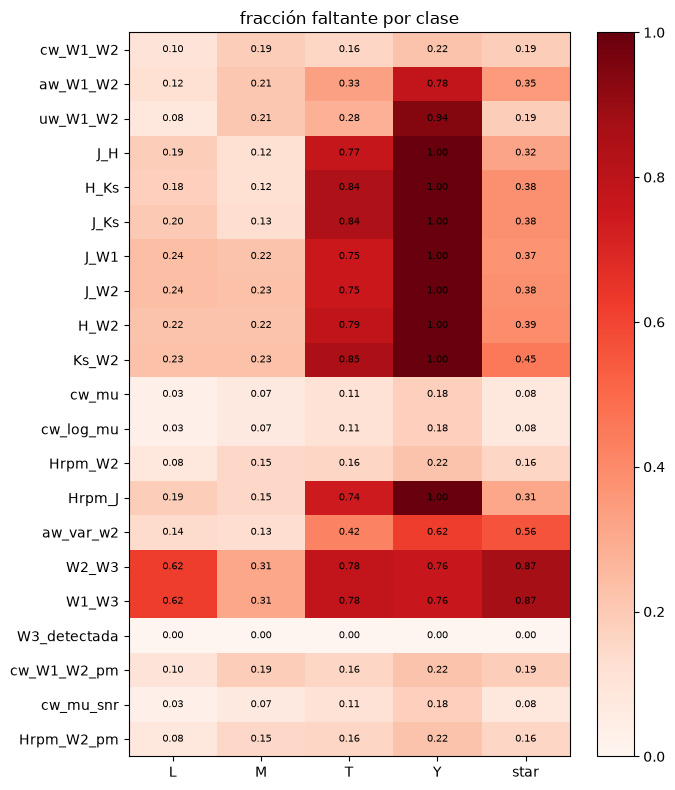

In [4]:
falt = feat.groupby("label")[e1].apply(lambda x: x.isna().mean()).T.round(2)
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(falt.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(falt)), falt.index); ax.set_xticks(range(falt.shape[1]), falt.columns)
for i in range(falt.shape[0]):
    for j in range(falt.shape[1]):
        ax.text(j, i, f"{falt.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("fracción faltante por clase"); plt.colorbar(im); plt.tight_layout(); plt.show()

## 4. Distribución de variables clave por clase

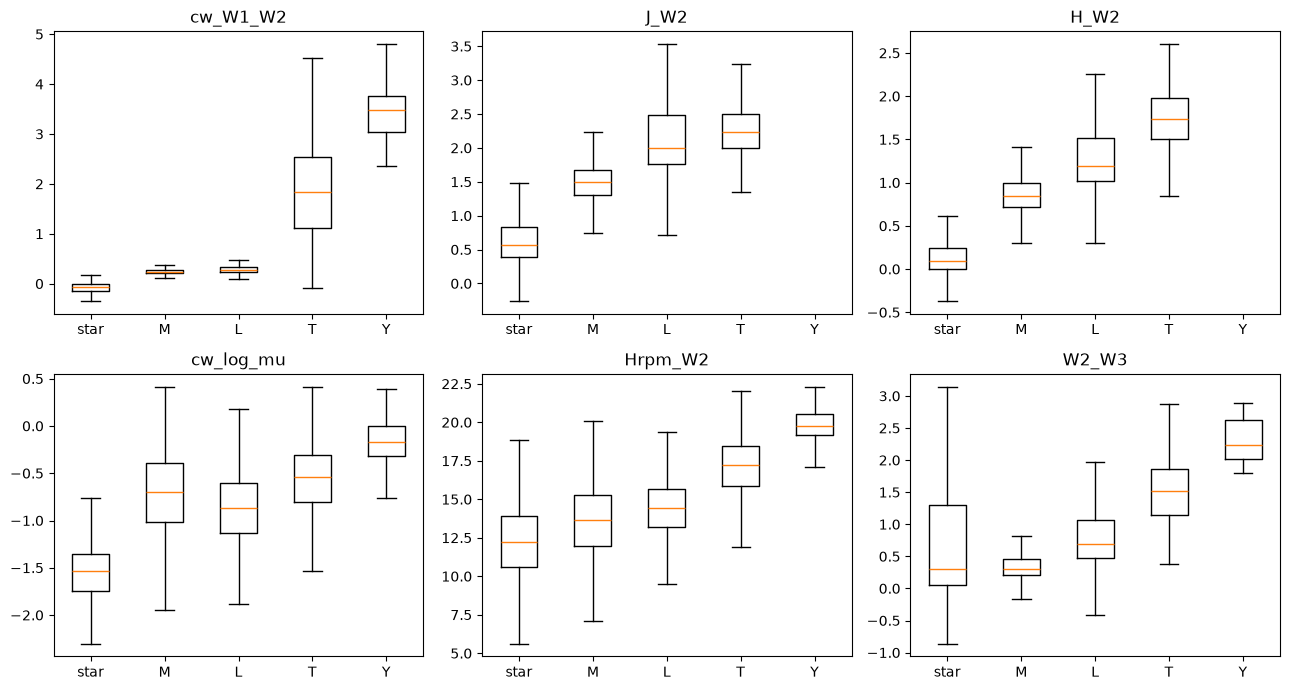

In [5]:
clave = [c for c in ["cw_W1_W2", "J_W2", "H_W2", "cw_log_mu", "Hrpm_W2", "W2_W3"] if c in feat.columns]
orden = ["star", "M", "L", "T", "Y"]
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axs.ravel(), clave):
    data = [pd.to_numeric(feat.loc[feat.label == k, c], errors="coerce").dropna() for k in orden]
    ax.boxplot(data, tick_labels=orden, showfliers=False)
    ax.set_title(c)
plt.tight_layout(); plt.show()

## 5. Variables SPHEREx (si existen)

(850, 43)
       spx_c21  spx_c32  spx_c43  spx_c54  spx_c65  spx_c64  spx_ch4  spx_ch4_limite
label                                                                               
L        -1.30    -0.37     0.26    -0.11     0.54     0.44     0.04             0.0
M        -1.24    -0.08     0.43     0.03     0.46     0.53    -0.01             0.0
T        -0.82     0.12     0.04    -1.16     0.58    -0.38     0.58             0.0
Y        -0.12     0.10     0.21    -0.91    -0.03    -0.51     0.55             0.0
star     -0.16     0.25     0.67     0.55     0.31     0.85    -0.22             0.0
cobertura:
       spx_c21  spx_c32  spx_c43  spx_c54  spx_c65  spx_c64  spx_ch4  spx_ch4_limite
label                                                                               
L         0.62     0.88     0.88     0.85     0.68     0.68     0.85            0.91
M         0.85     0.91     0.91     0.91     0.89     0.87     0.91            0.99
T         0.23     0.38     0.37     0.43   

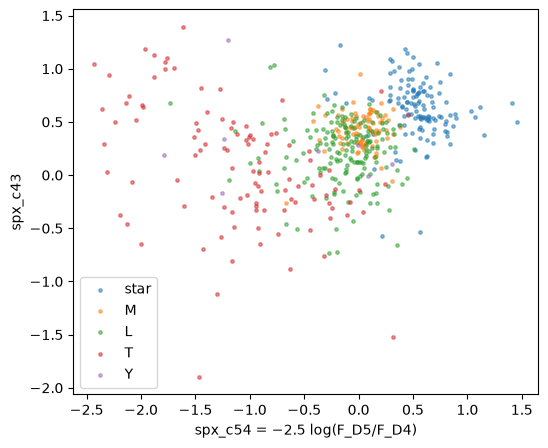

In [6]:
f = SAL / "3_features_spherex" / "features_spherex.parquet"
if f.is_file():
    spx = pd.read_parquet(f)
    cols = [c for c in spx.columns if c.startswith("spx_c") or c == "spx_ch4"]
    print(spx.shape); print(spx.groupby("label")[cols].median().round(2))
    print("cobertura:"); print(spx.groupby("label")[cols].apply(lambda x: x.notna().mean()).round(2))
    fig, ax = plt.subplots(figsize=(6, 5))
    for k in orden:
        s = spx[spx.label == k]
        ax.scatter(s["spx_c54"], s["spx_c43"], s=6, alpha=.5, label=k)
    ax.set_xlabel("spx_c54 = −2.5 log(F_D5/F_D4)"); ax.set_ylabel("spx_c43"); ax.legend(); plt.show()
else:
    print("Aún no hay variables SPHEREx: correr las etapas 1–3 (python -m motor --etapas 1_indice_spherex 2_fotometria_spherex 3_features_spherex)")

## 6. Posiciones en el cielo: desarrollo y test

El test son celdas de cielo enteras: ningún objeto de una celda de test se usa para entrenar.

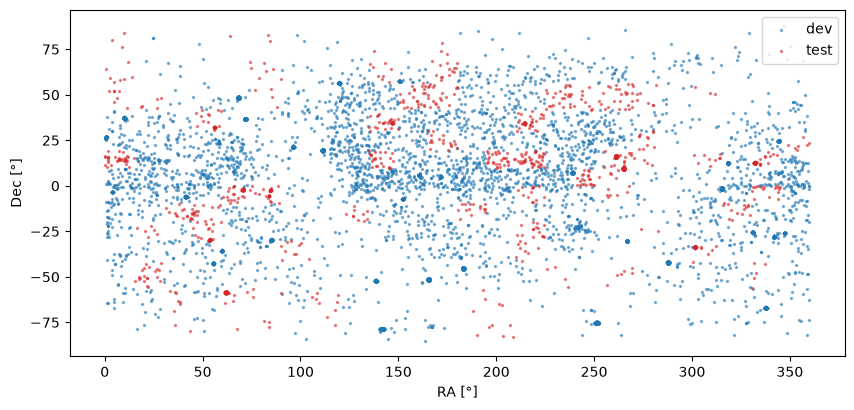

In [7]:
t = feat[["oid", "ra", "dec"]].merge(part[["oid", "role"]], on="oid")
fig, ax = plt.subplots(figsize=(10, 4.5))
for r, col in (("dev", "tab:blue"), ("test", "tab:red")):
    s = t[t.role == r]; ax.scatter(s.ra, s.dec, s=2, c=col, label=r, alpha=.5)
ax.set_xlabel("RA [°]"); ax.set_ylabel("Dec [°]"); ax.legend(); plt.show()